# 02 · Stage 2 — Aggregate and impute

Stage 2 takes the three feed runs of Stage 1 (each a value and a σ per edge it observes) and returns one prior for every edge of the accounting structure: the observed edges pooled by inverse variance, every other edge filled by an imputer, and an imputation log that says who wrote what.

> **What this stage assumes**
> - **A2** Feeds combine by inverse variance, and every σ composition is one power-mean rule with $p = 1.3$ (Eq. 1).
> - **A8** An edge that no feed and no imputer covers is a flat prior at value 0 with a large σ: a noisy zero. The framework never guesses a value.
> - **A9** Imputation fills are write-once and logged with method, source edges and coefficients.
> - **A5** No stage drops σ: every fill carries its value and its σ together.
> - Copper's choice: its cascade also runs the trade-share and stock-change seeds and a size-damped σ on bilateral legs, and 79.7 % of its edges end on the flat prior; the toy's cascade is the same three steps at a scale you can read (manuscript Table 2, §3.1.4).

In [1]:
import json
import logging
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto import acc_store
from pysuto.tutorial import toy
from pysuto.diag import AggDiagnostic, ImpDiagnostic
from pysuto.registry import ImputationRunRegistry

RUNS = Path("runs")
PROC = RUNS / "proc"
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 60)
logging.disable(logging.INFO)

Chapter 01 left three feed runs in `runs/`. This chapter runs only Stage 2 on top of them. The toy departs from copper in three plain ways here: it declares its own labels (`Gross` and `Content`), its cascade is copper's at toy scale, and its world is closed, with no `ROW`.

## The run we are reading

In [2]:
imp_id = toy.run_stage2(RUNS)
reg = ImputationRunRegistry(str(PROC / "imp"))
agg = reg.load(imp_id)
acc = acc_store.load("toy", storage_dir=str(PROC / "acc"))
em = acc.edge_meta.set_index("edge_id")
em["edge"] = acc.edge_labels()
print(imp_id, "| feeds:", agg.feed_ids, "| edges:", agg.n_edges)

AggDiagnostic (toy)
  covered edges: 93 / 420
  f_agg  : p50=3.28  p99=2.96e+03  max=2.38e+04
  σ_agg  : p50=0.265  p99=508  max=4.98e+03
  CV_agg : p50=0.0684  p90=0.209  p99=0.209  max=0.209
  top-5 (feed, edge) by σ_root:
    feed='customs' edge=194  f=2.38e+04  σ=4.98e+03  CV=0.209
    feed='survey' edge=6  f=1.15e+03  σ=120  CV=0.104
    feed='survey' edge=4  f=1e+03  σ=104  CV=0.104
    feed='survey' edge=0  f=978  σ=102  CV=0.104
    feed='survey' edge=8  f=972  σ=101  CV=0.104


────────────────────────────────────────────────────────────
  IMPUTATION DIAGNOSTICS — imp_20261123_171602_87bc50df
────────────────────────────────────────────────────────────
  Root edges total       :      420
  Covered after cascade  :      420  (100.0 %)
  Filled by imputers     :      327  (77.9 %)
  Still missing          :        0  (0.0 %)

  Fills per step:
    s0 trade·p1         trade_seed                  15 fills
    s1 network·p1       network_mass_twin          190 fills
    s2 conc·p1          parametric                  26 fills
    s3 time_interp      time_linear                 46 fills
    s4 flat_prior       flat_prior_noisy_zero       50 fills
────────────────────────────────────────────────────────────
imp_20261123_171602_87bc50df | feeds: ['survey', 'bureau', 'customs'] | edges: 420


`agg` is the aggregation result: one row per feed in `F` (value) and `Sigma` (σ), shape feeds × edges, with NaN where a feed does not observe the edge. Everything below reads it.

## The coverage mask

The coverage mask records which edges *any feed* observed, before any imputation. Count them per feed.

In [3]:
seen = ~np.isnan(agg.F)
by_feed = pd.Series(seen.sum(axis=1), index=agg.feed_ids, name="edges observed")
print(by_feed.to_string())
print(f"sum over feeds {seen.sum()}  vs  covered {int(agg.coverage.sum())} of {agg.n_edges} edges")
print(f"edges seen by two feeds: {int((seen.sum(axis=0) == 2).sum())}")

survey     10
bureau     73
customs    15
sum over feeds 98  vs  covered 93 of 420 edges
edges seen by two feeds: 5


The feeds add up to more edges than are covered: five edges are observed twice. They are the one place where the aggregation has something to do.

## Inverse-variance aggregation

Isla's `Deposit → Mining` edge in `Gross` is reported by the Survey (as its ore extraction) and by the Bureau (a table of its own), in all five years. Take 2003.

In [4]:
mask = ((em["from_sector"] == "Deposit") & (em["from_region"] == "Isla")
        & (em["to_sector"] == "Mining") & (em["valuation"] == "Gross")
        & (em["time"] == "2003"))
j = int(em.index[mask][0])
obs = pd.DataFrame({"value (kt)": agg.F[:, j], "σ (kt)": agg.Sigma[:, j],
                    "weight Ω": agg.Omega[:, j]}, index=agg.feed_ids)
obs

,value (kt),σ (kt),weight Ω
survey,379.770323,39.624824,0.341361
bureau,417.251702,28.526611,0.658639
customs,NaN,NaN,0.000000


Two observations; the Customs feed does not see this edge. The Bureau is the tighter one (smaller σ), so it gets the larger weight $\Omega_k = \sigma_k^{-2} / \sum_k \sigma_k^{-2}$. The pooled value is the weighted mean, and the pooled σ is Eq. (1) over the weighted contributions $\Omega_k \sigma_k$:

$$\sigma_\oplus = \Bigl(\sum\nolimits_k \lvert \Omega_k \sigma_k \rvert^{p}\Bigr)^{1/p}, \qquad p = 1.3 \tag{1}$$

In [5]:
w = obs["weight Ω"].fillna(0.0)
s = obs["σ (kt)"].fillna(0.0)
value = (w * obs["value (kt)"].fillna(0.0)).sum()
sigma = ((w * s) ** 1.3).sum() ** (1 / 1.3)
print(f"by hand : value {value:.2f} kt, σ {sigma:.2f} kt")
print(f"stage 2 : value {agg.f_agg[j]:.2f} kt, σ {agg.sigma_agg[j]:.2f} kt")

by hand : value 404.46 kt, σ 27.65 kt
stage 2 : value 404.46 kt, σ 27.65 kt


By hand and by stage agree. The pooled value sits between the two observations, nearer the Bureau's. The pooled σ is *slightly* below the Bureau's own: two observations help a little, not a lot. Why only a little is the going-deeper box.

In [6]:
quad = 1 / np.sqrt((1 / s[s > 0] ** 2).sum())
print(f"Bureau alone {s['bureau']:.2f} kt | Eq. (1) at p = 1.3: {sigma:.2f} kt "
      f"| plain quadrature (p = 2): {quad:.2f} kt")

Bureau alone 28.53 kt | Eq. (1) at p = 1.3: 27.65 kt | plain quadrature (p = 2): 23.15 kt


<details><summary>Going deeper: why p = 1.3 pools so little</summary>

At $p = 2$ Eq. (1) is the Gaussian quadrature of independent errors, and with precision weights it reduces to $1/\sqrt{\sum_k \sigma_k^{-2}}$: the textbook result that two independent observations are worth more than either. That is the last number of the cell above, well below both inputs.

pySUTO uses $p = 1.3$ in every stage (A2). The reason is the modelling claim of the manuscript (§3.1.2): contributions that meet on one edge rarely err independently — two agencies read the same mines, the same customs ledgers — so the aggregate gets less diversification credit than independence would give. At $p = 1$ the combine is a plain weighted sum of σ's and the pooled σ is a weighted mean of the inputs; at $p = 1.3$ it lies just under the better input.

Two consequences. First, no pooled σ ever exceeds the largest input, so adding a feed never makes an edge less certain. Second, the toy's overlap is placed on Isla because there the pooled σ is below both inputs in every year; on Montara the same pair would not pass that test. The Lp exponent is a judgement value; the knob sweep of the manuscript varies it between 1.1 and 1.5.
</details>

## The cascade

The aggregation covers 93 of 420 edges. Everything else is a fill, and every fill writes one row of the imputation log. The log is a table with one row per filled edge; here are the rows per step and method.

In [7]:
log = agg.imputation_log.as_dataframe()
log["edge"] = log["edge_id"].map(em["edge"])
log["time"] = log["edge_id"].map(em["time"])
print(f"{len(log)} fills = {len(log)} distinct edges: {log['edge_id'].is_unique}")
print("committed steps:", sorted(int(k) for k in log["step"].unique()))
log.groupby(["step", "imputer_id", "method"]).size().rename("fills").to_frame()

327 fills = 327 distinct edges: True
committed steps: [0, 1, 2, 3, 4]


fills
step imputer_id  method                         
0    trade       trade_seed                   15
1    network     network_backward             73
                 network_backward_capped       2
                 network_backward_clipped      3
                 network_balance              10
                 network_mass_twin            90
                 network_mass_twin_capped      4
                 network_stripping             8
2    conc        parametric                   26
3    time_interp time_linear                  46
4    flat_prior  flat_prior_noisy_zero        50

Steps 0–2 are the **cascade**: three imputers swept in a fixed order until a sweep fills nothing new (here one pass is enough). The engine does run a second sweep to prove it, sees that it fills nothing, and discards that pass with its step numbers (it logs the discard): only committed steps are recorded, so the log counts 0–4. Steps 3–4 are the **terminal pass**, run once. Each imputer writes only edges that are still empty, so a fill is never overwritten (A9).

### Step 0 — the trade twin

Customs reports bilateral concentrate legs in `Gross`; Stage 2 needs them in `Content` too. The trade fill writes each leg's content twin from its observed gross mass, $\text{Content} = \text{conc} \times \text{Gross}$, with the concentrate grade from the `conc` parameters. 2005:

In [8]:
year = "2005"
t = log[(log["method"] == "trade_seed") & (log["time"] == year)].copy()
t["gross twin (kt)"] = [agg.f_agg[int(sr[0])] for sr in t["source_edges"]]
t["× grade"] = [c[0] for c in t["coefficients"]]
t[["edge", "gross twin (kt)", "× grade", "f_after"]].rename(columns={"f_after": "content (kt Content)"})

,edge,gross twin (kt),× grade,content (kt Content)
4,Concentrate|Isla → Smelting|Portua (Content),1.545029,0.28,0.432608
9,Concentrate|Montara → Smelting|Isla (Content),2.970059,0.28,0.831617
14,Concentrate|Montara → Smelting|Portua (Content),23.361510,0.28,6.541223


Each content value is the grade times its gross twin. Only legs Customs reports get a twin; a leg Customs does not mention stays empty and will end on the flat prior.

### Step 1 — recipe closure and reverse efficiency

The `network` step walks the processes. A process's product equals its recovery efficiency times its pooled inputs; the residual output gets the complement; the gross and content values of one edge are tied by the grade. Wherever one side of a recipe is known, the network writes the other. Montara in 2005, the whole step:

In [9]:
net = log[(log["step"] == 1) & (log["time"] == year) & log["edge"].str.contains("Montara → ")]
net[["edge", "method", "f_after", "sigma_after"]].rename(columns={"f_after": "value", "sigma_after": "σ"})

,edge,method,value,σ
24,Deposit|Montara → Mining|Montara (Content),network_backward,11.126019,0.760631
25,Mining|Montara → WasteRock|Montara (Content),network_backward,0.000000,0.000000
26,Mining|Montara → Ore|Montara (Gross),network_mass_twin,1112.601906,160.483421
54,Ore|Montara → Milling|Montara (Content),network_backward,10.775050,0.837815
55,Milling|Montara → Tailings|Montara (Content),network_backward,1.077505,0.083782
56,Ore|Montara → Milling|Montara (Gross),network_mass_twin,1077.505038,163.603729
57,Milling|Montara → Concentrate|Montara (Gross),network_mass_twin,34.634091,4.126318
58,Milling|Montara → Tailings|Montara (Gross),network_mass_twin,1077.505038,262.572472
97,Concentrate|Montara → Smelting|Montara (Content),network_backward,1.975323,0.182182
98,Smelting|Montara → Slag|Montara (Content),network_backward,0.076268,0.004894


Two methods carry the idea. `network_mass_twin` writes a gross edge from its content twin through the grade. `network_backward` runs a recipe *in reverse*: when the product is observed, the pooled input is the product divided by the efficiency. The recipe is pooled: Smelting's recovery applies to concentrate and scrap together. One check by hand: Montara's smelter, its metal out times $1/\text{eff}$ against everything that goes in.

In [10]:
smelt = em[(em["to_sector"] == "Smelting") & (em["to_region"] == "Montara")
           & (em["valuation"] == "Content") & (em["time"] == year)]
metal = em[(em["from_sector"] == "Smelting") & (em["to_sector"] == "Metal")
           & (em["from_region"] == "Montara") & (em["valuation"] == "Content") & (em["time"] == year)]
inputs = pd.Series(agg.f_agg[smelt.index], index=smelt["edge"])
print(inputs.round(3).to_string())
print(f"Σ inputs {inputs.sum():.3f} = metal out {agg.f_agg[metal.index[0]]:.3f} / 0.97 = "
      f"{agg.f_agg[metal.index[0]] / 0.97:.3f}")

edge
Concentrate|Montara → Smelting|Montara (Content)    1.975
Concentrate|Portua → Smelting|Montara (Content)     0.000
Concentrate|Isla → Smelting|Montara (Content)       0.000
Scrap|Montara → Smelting|Montara (Content)          0.567
Σ inputs 2.542 = metal out 2.466 / 0.97 = 2.542


The concentrate from Isla and Portua is a noisy zero (step 4, below), the scrap is the Bureau's, and the network wrote the rest. The waste-rock edge (`Mining → WasteRock`, `network_stripping`) is filled from the stripping ratio, not from a recipe: it is a satellite, outside Mining's balance (A10, chapter 03).

### Step 2 — the concentration fill

The last cascade step ties the two valuations wherever only one is known. Metal's content is observed on its way to `Use` and `Stock`; the gross twin follows from the metal grade.

In [11]:
c2 = log[(log["step"] == 2) & (log["time"] == year)]
c2[["edge", "method", "source_edges", "coefficients", "f_after"]].head(4)

,edge,method,source_edges,coefficients,f_after
208,Metal|Isla → Stock|Isla (Gross),parametric,[419],[1.0101010101010102],0.138839
212,Metal|Isla → Use|Isla (Gross),parametric,[409],[1.0101010101010102],3.921121
216,Metal|Montara → Stock|Montara (Gross),parametric,[379],[1.0101010101010102],-0.227044
220,Metal|Montara → Use|Montara (Gross),parametric,[369],[1.0101010101010102],2.860476


## The terminal pass

### Step 3 — time interpolation

Two region-years are missing from the Bureau's content chain. The time imputer fills such a gap linearly from the neighbouring years: half the year before, half the year after. One edge, checked by hand:

In [12]:
tl = log[(log["method"] == "time_linear")
         & (log["edge"] == "Mining|Isla → Ore|Isla (Content)")].iloc[0]
a, b = (int(x) for x in tl["source_edges"])
print(f"{em.at[a, 'edge']}  {agg.f_agg[a]:.3f}")
print(f"{em.at[b, 'edge']}  {agg.f_agg[b]:.3f}")
print(f"mean {(agg.f_agg[a] + agg.f_agg[b]) / 2:.3f}  vs  log {tl['f_after']:.3f}")

Mining|Isla → Ore|Isla (Content)  3.280
Mining|Isla → Ore|Isla (Content)  3.169
mean 3.224  vs  log 3.224


The σ of a fill is not free either: the two neighbours' σ combined by Eq. (1) with weights ½, inflated by 5 % per year of the span between the two neighbours.

In [13]:
sa = np.array([agg.sigma_agg[a], agg.sigma_agg[b]])
span = int(em.at[b, "time"]) - int(em.at[a, "time"])
by_hand = (((0.5 * sa) ** 1.3).sum() ** (1 / 1.3)) * 1.05 ** span
print(f"span {span} years")
print(f"by hand {by_hand:.4f}  vs  log {tl['sigma_after']:.4f}")

span 2 years
by hand 0.2071  vs  log 0.2071


The imputer interpolates only; at the ends of a series it writes nothing (`TIME_INTERPOLATE_ONLY`). Exercise 2.1 below asks for every region-year it touched.

### Step 4 — the flat prior, and Portua

What nothing has filled gets a **noisy zero**: value 0, σ $= 10^6$ (A8). The honest case in the toy is Portua, which mines nothing. No feed reports an extraction there and no recipe produces one. Portua's mine chain in 2003, in both valuations:

In [14]:
ids = em[(em["from_region"] == "Portua") & em["from_sector"].isin(["Deposit", "Mining"])
         & (em["time"] == "2003")].index
chain = log[log["edge_id"].isin(ids)]
chain[["edge", "method", "f_after", "sigma_after"]].rename(columns={"f_after": "value", "sigma_after": "σ"})

,edge,method,value,σ
184,Mining|Portua → Ore|Portua (Content),network_balance,0.0,7486.124411
191,Deposit|Portua → Mining|Portua (Content),network_backward,0.0,7485.812515
192,Mining|Portua → WasteRock|Portua (Content),network_backward,0.0,0.000000
279,Deposit|Portua → Mining|Portua (Gross),flat_prior_noisy_zero,0.0,1000000.000000
284,Mining|Portua → Ore|Portua (Gross),flat_prior_noisy_zero,0.0,1000000.000000
289,Mining|Portua → WasteRock|Portua (Gross),flat_prior_noisy_zero,0.0,1000000.000000


Every edge of the chain is a zero with a σ of thousands to a million, except the content of the waste rock, which is zero by definition (its concentration row gives it grade 0): the prior says "nothing", and says it very loosely. It is a *noisy* zero, not a measured one. Stage 3 will anchor it (chapter 03). The same step also gives the noisy zero to the concentrate legs no feed reports, 50 edges in all.

## The imputation log as an audit trail

Any edge of the prior can be traced. One row of the log, in full:

In [15]:
log[(log["edge"] == "Metal|Montara → Use|Montara (Gross)") & (log["time"] == year)].iloc[0]

edge_id                                                                   368
step                                                                        2
imputer_id                                                               conc
pass                                                                      1.0
method                                                             parametric
source_edges                                                            [369]
coefficients                                             [1.0101010101010102]
f_before                                                                  NaN
f_after                                                              2.860476
sigma_before                                                              NaN
sigma_after                                                          0.198683
description       orium content of Metal (Flow) on the edges out of it, ev...
param_id                                                      co

`step` and `imputer_id` say who, `method` how, `source_edges` and `coefficients` from what, `f_before`/`f_after` and `sigma_before`/`sigma_after` the change, `param_id` which parameter row supplied the ratio. The log is persisted with the run (`imputation_log.parquet`), so it is the answer to "where did this prior come from?" for every one of the 420 edges: the feed, or one imputer.

<details><summary>Going deeper: provenance and write-once fills</summary>

Each imputer writes only edges whose value is still NaN when it runs, and the log keeps exactly one row per filled edge (the cell printing the fill table checks it). Order therefore decides precedence: the trade twin beats the network, which beats the concentration fill, which beats the time imputer, which beats the flat prior. A fill is a value-with-σ pair, so a later stage can always ask how much to trust it.

The log also records `relaxed` and `assumed_absent`, used by copper's relaxed recipe close (ADR 0010); in the toy both are empty. Methods suffixed `_capped` mean the fill's σ was cut at the cap `NETWORK_CV_CAP` times its value; `_clipped` means the fill was floored at the edge's lower bound and its σ widened to the clip gap; the table above shows a few in the toy. In the diagnostics, step ids read `sN <imputer>·pP`: step N, pass P of the cascade.

The toy has no `ROW`, so the geographic pedigree penalty of ADR 0003 never fires; copper's flat prior for ROW edges is penalised quadrature-added to the flat σ.
</details>

## Figures from the diagnostics

`AggDiagnostic` shows what the feeds brought; `ImpDiagnostic` shows what each step added. Both take the focus `year` explicitly.

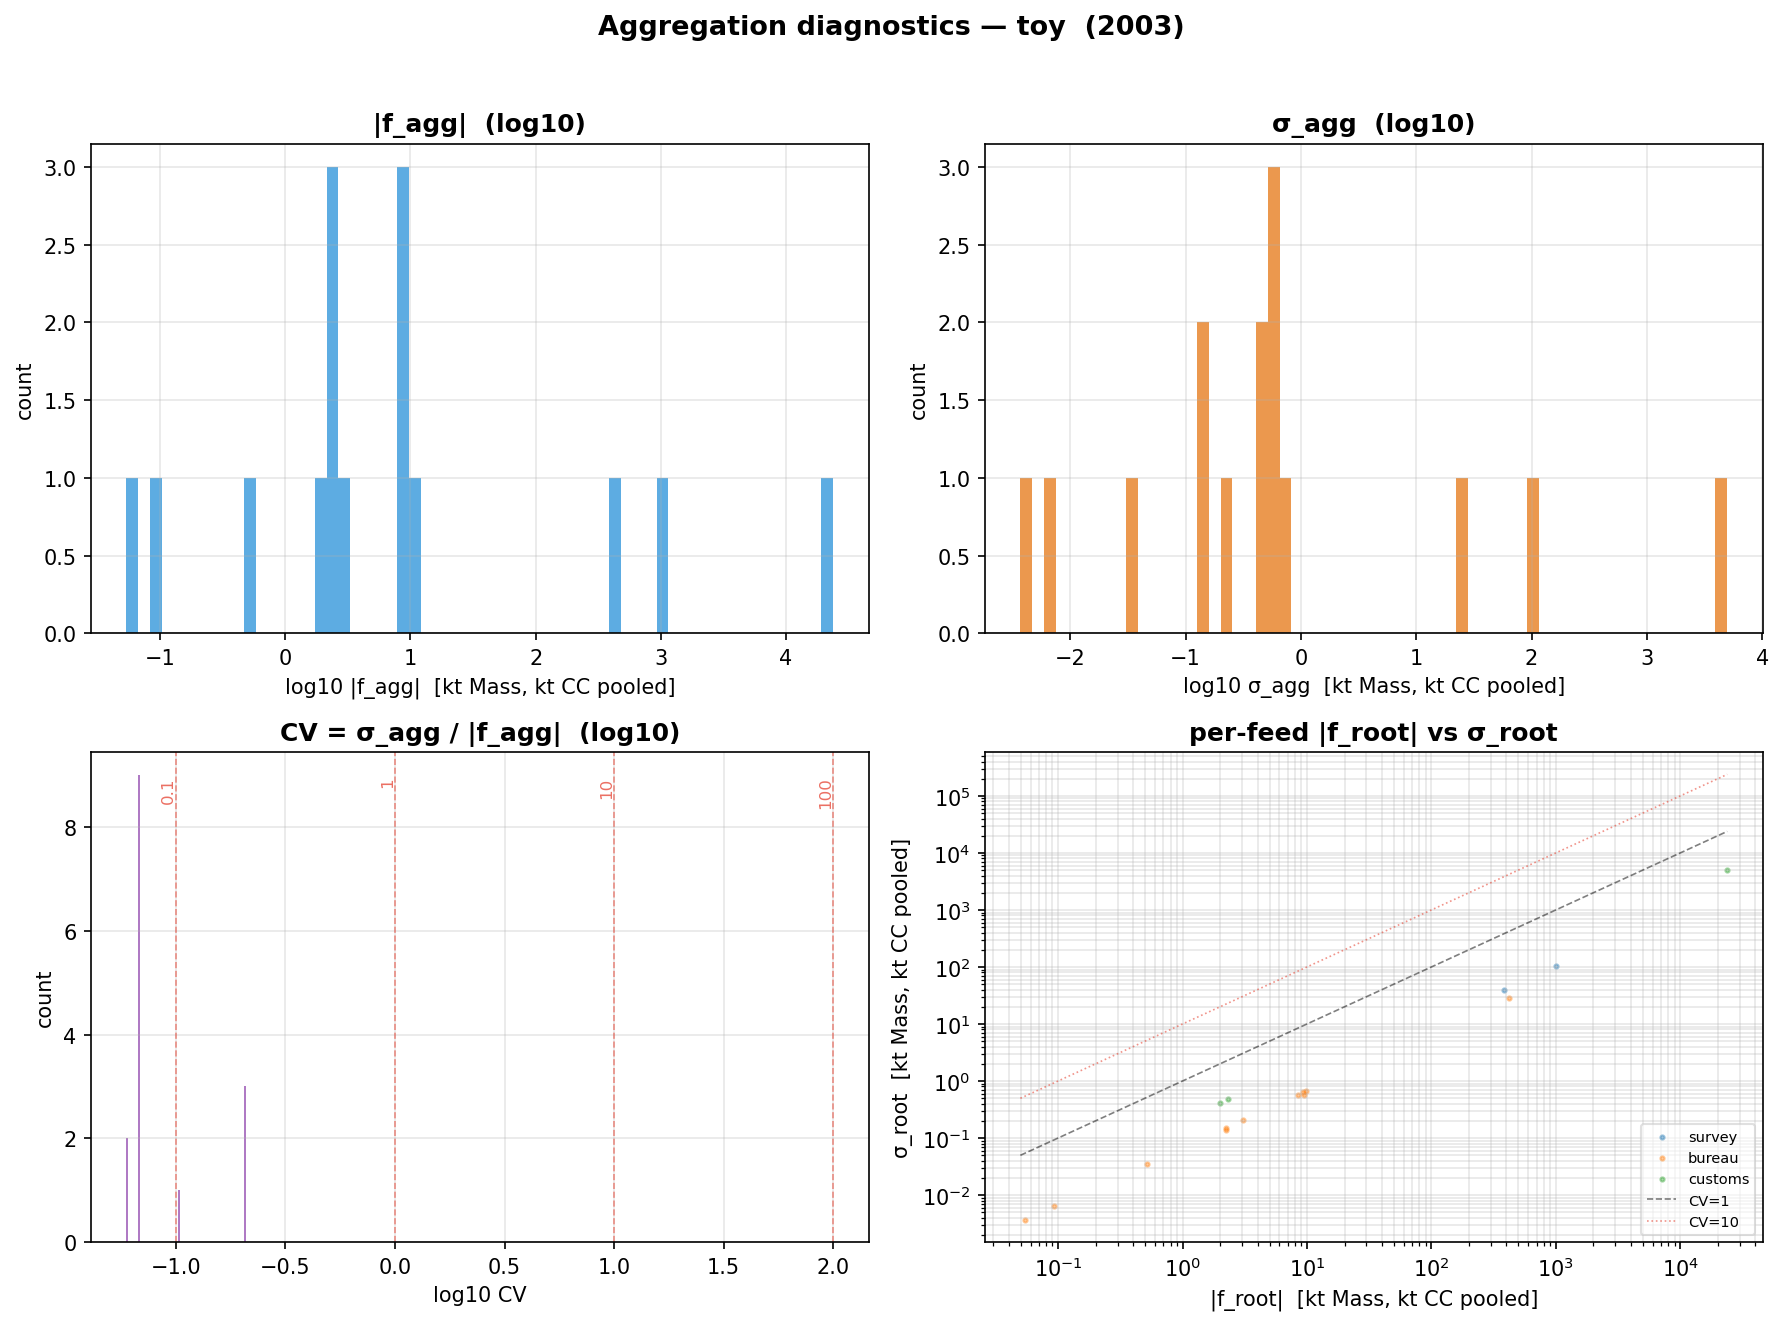

In [16]:
FIGS = RUNS / "figs"
FIGS.mkdir(parents=True, exist_ok=True)
AggDiagnostic(agg, acc_struct=acc, label="toy", year="2003").plot(odir=str(FIGS), show=False)
display(Image(str(FIGS / "agg_distributions.png")))

Per-feed observations in 2003: the feed-observed edges only, a few dozen points. Their CVs are the pedigree CVs of chapter 01, about 0.07 to 0.2.

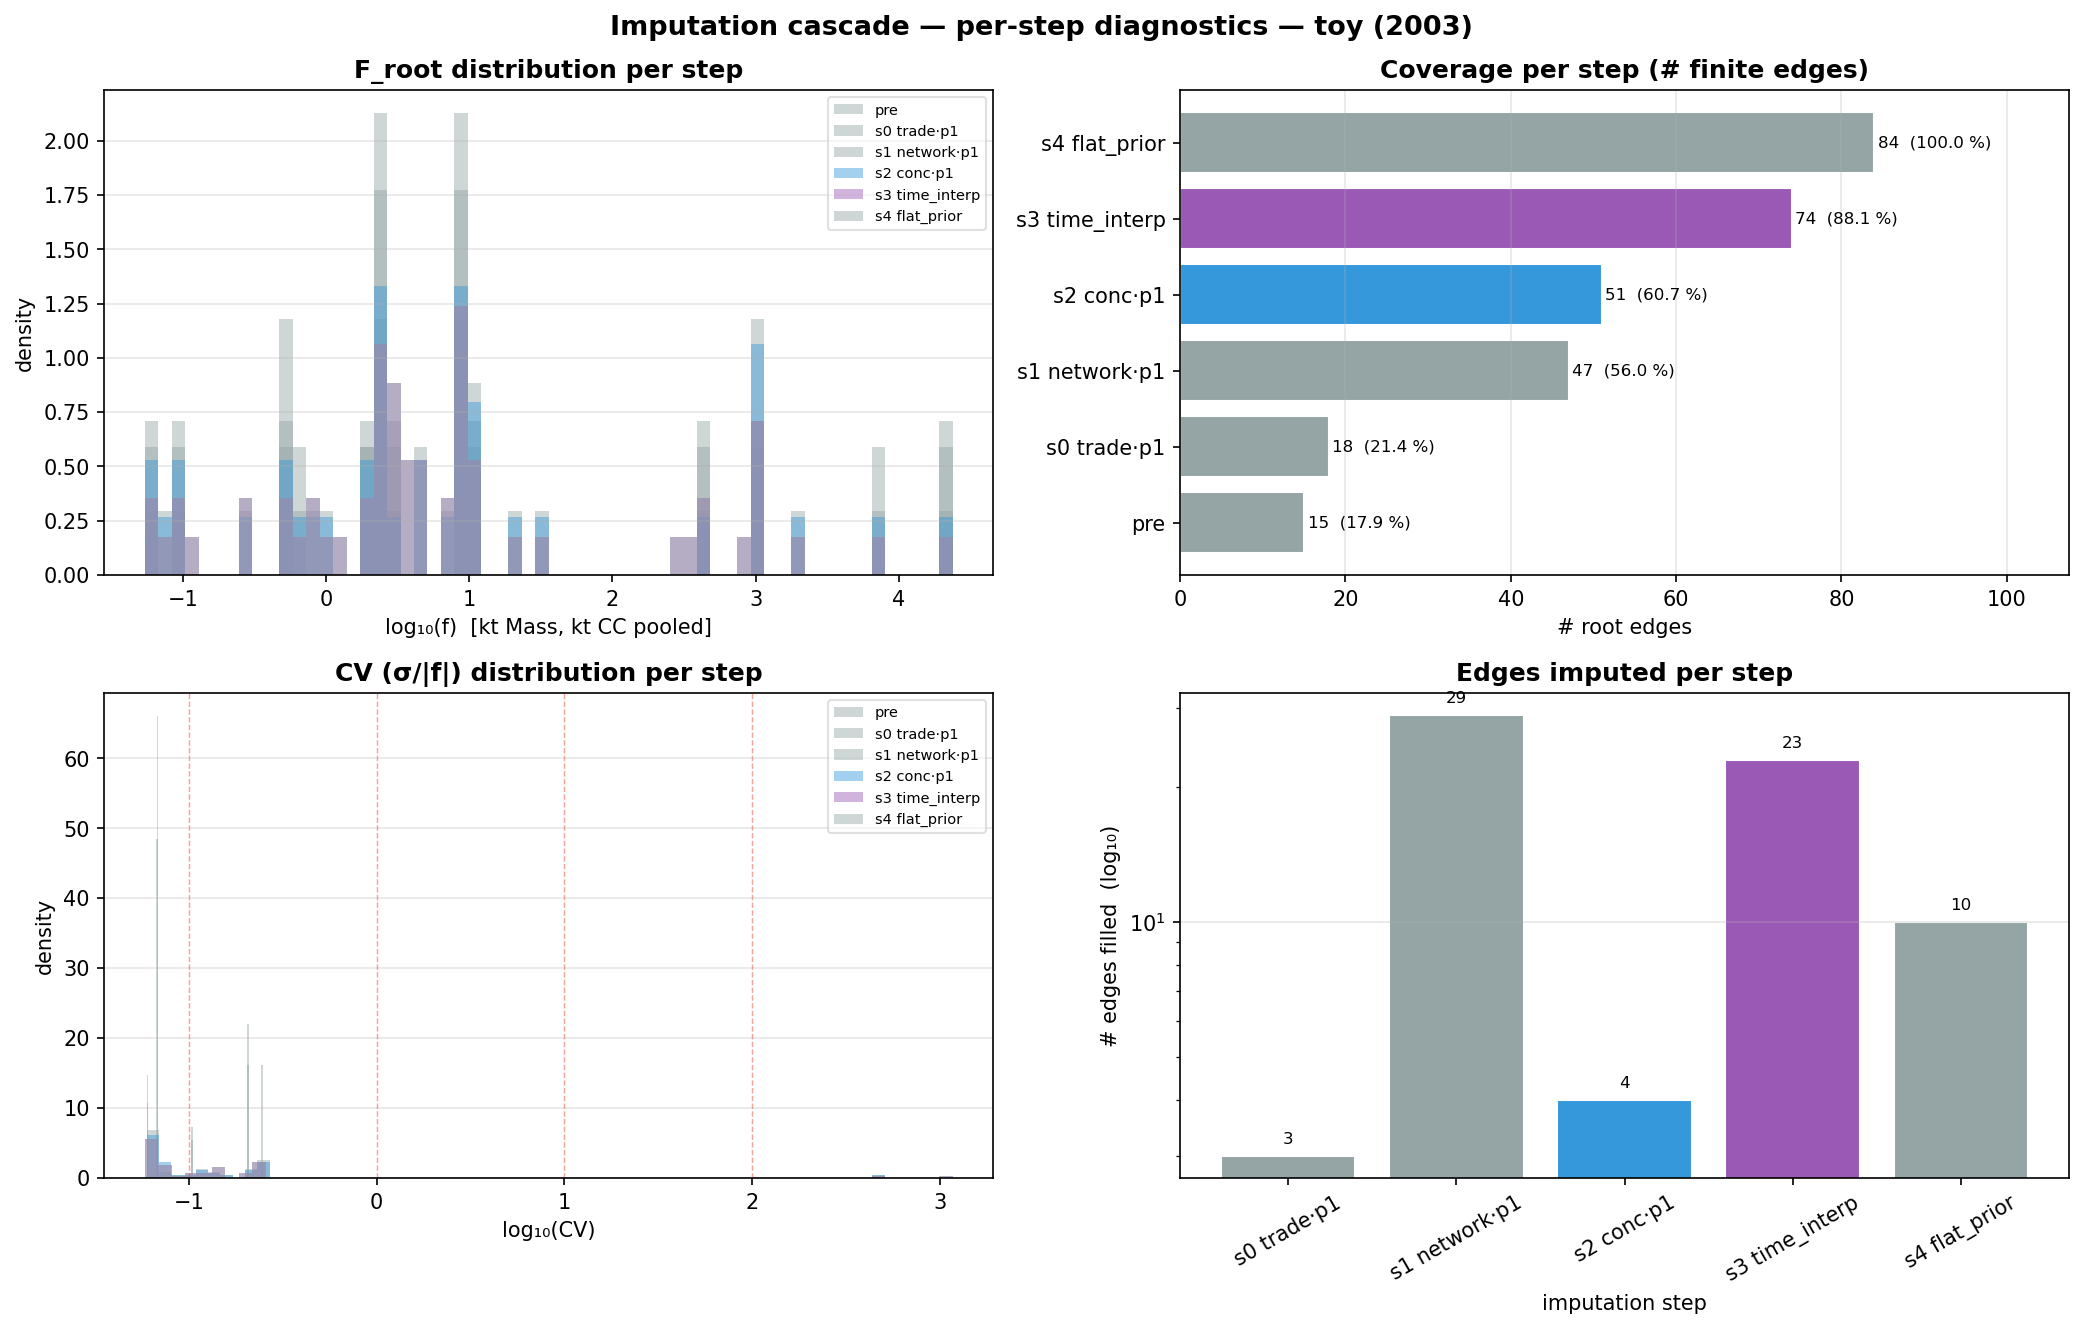

In [17]:
ImpDiagnostic(agg, acc_struct=acc, label="toy", year="2003").plot(odir=str(FIGS), show=False)
display(Image(str(FIGS / "imputation_steps.png")))

Bottom right: edges imputed per step in 2003. Top right: coverage climbs from the observed edges (`pre`) to 100 % at the flat prior. Time-interpolated points, orange crosses between grey observed ones:

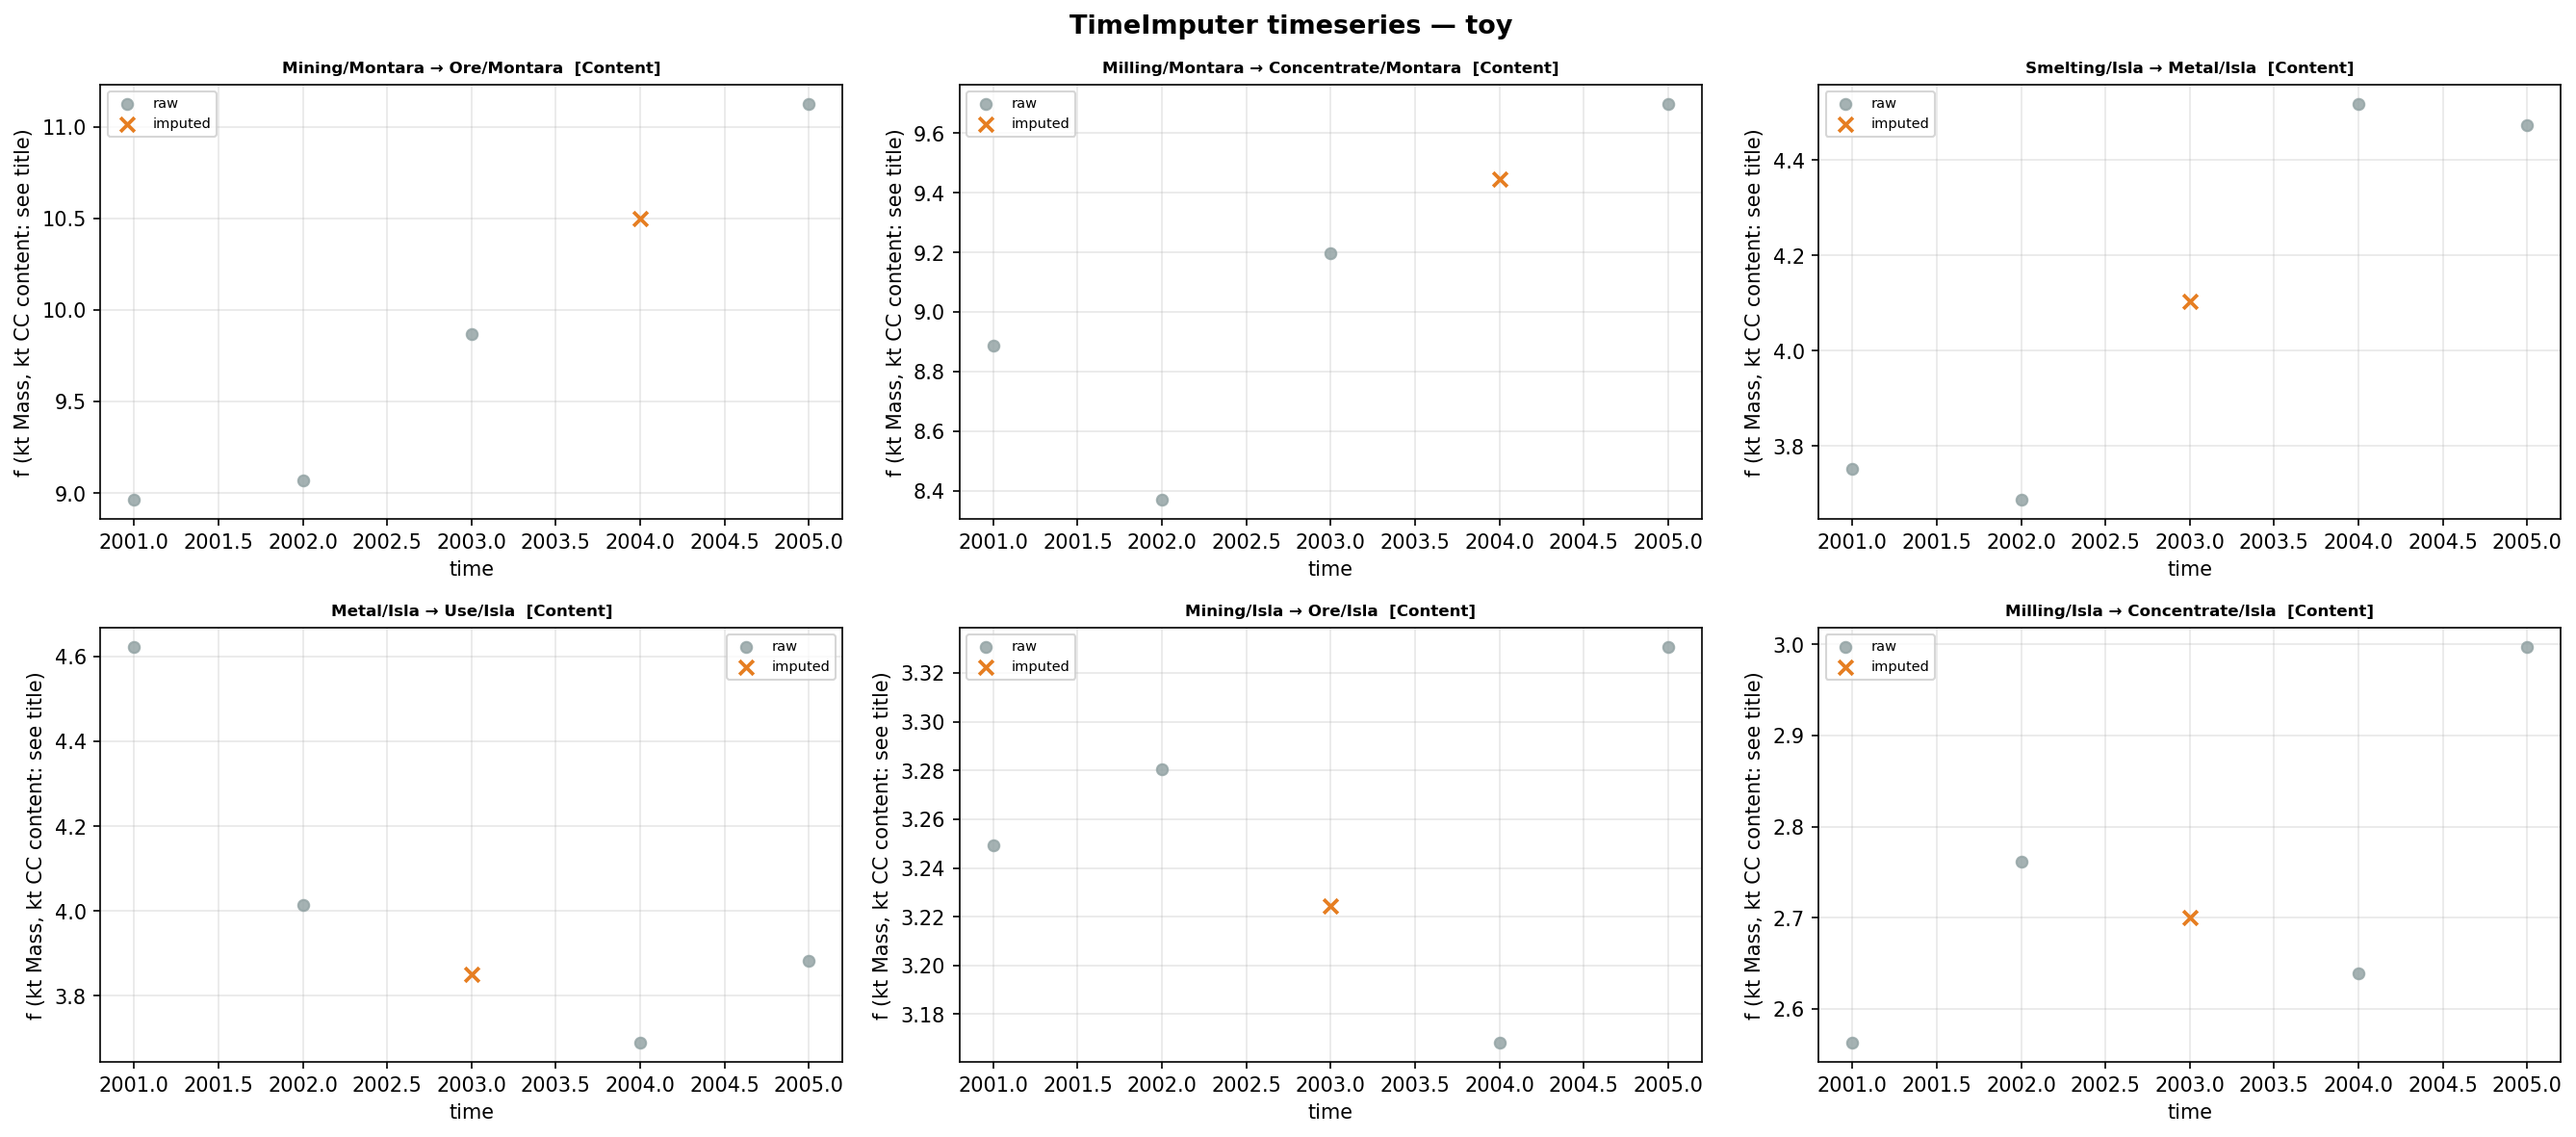

In [18]:
display(Image(str(FIGS / "imputation_timeseries.png")))

**Exercise 2.1** — Find the region-years the time imputer filled (the Bureau's two gaps): read the imputation log for the rows of `time_interp`, take each edge's region and year from `em`, and check them with `toy.check_2_1`. Cover the next cell and try it first; `toy.solution("2.1")` prints the reference.

In [19]:
filled = log.loc[log["imputer_id"] == "time_interp", "edge_id"]
rows = em.loc[filled]
pairs = set(zip(rows["from_region"], rows["time"]))
print(toy.check_2_1(RUNS, pairs))

✓ 2.1  the time imputer filled [('Isla', '2003'), ('Montara', '2004')]


## Where this run came from

In [20]:
meta = json.loads((PROC / "imp" / imp_id / "metadata.json").read_text())
print("parents.inputs  :", {k: (v if isinstance(v, dict) else [x["id"] + " v" + str(x["version"]) for x in v])
                            for k, v in meta["parents"]["inputs"].items()})
print("parents.upstream:", meta["parents"]["upstream"])
print("stage_summary   :", meta["stage_summary"])

parents.inputs  : {'acc': {'id': 'toy', 'version': 1, 'date': '2026-11-23T17:15:56Z', 'code': '3e661eae', 'label': 'toy'}, 'params': ['conc v1', 'eff v1', 'stripping_ratio v1']}
parents.upstream: {'feed_run_ids': ['feed_survey_20261123_171558_440b41ea', 'feed_bureau_20261123_171558_c310f025', 'feed_customs_20261123_171558_2ba370e1']}
stage_summary   : {'cascade_passes_run': 1, 'n_total': 420, 'n_covered_before': 93, 'n_covered_after': 420, 'n_imputed': 327, 'n_steps': 5}


The imputation run names its inputs (the accounting structure and the three parameter sets, each by version) and its three feed runs. Next: [chapter 03](03_constraints.ipynb), where the prior becomes rows.